
# Sales Prediction Using Python

## 1. Objective
The objective of this project is to build a machine learning model that predicts product sales based on advertising expenditure.

## 2. Dataset
Advertising.csv

## 3. Input Features
- TV advertising expenditure
- Radio advertising expenditure
- Newspaper advertising expenditure

## 4. Target Variable
Sales

## 5. Machine Learning Models
- Linear Regression
- Random Forest Regressor

## 6. Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared Score (R²)

## 7. Tools and Libraries
Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.


In [ ]:

%pip install numpy pandas matplotlib seaborn scikit-learn


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Basic imports successful!")


Basic imports successful!


In [4]:

df = pd.read_csv("Advertising.csv")

print("Dataset imported successfully!")


Dataset imported successfully!


In [5]:

df.head()


,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [6]:

print("Number of rows and columns:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])



Number of rows and columns: (200, 5)
Number of rows: 200
Number of columns: 5


In [7]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [8]:

df = df.drop(columns=["Unnamed: 0"])

print("Dataset after removing the extra column:")
print(df.head())

print("\nDataset shape:", df.shape)


Dataset after removing the extra column:
      TV  radio  newspaper  sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9

Dataset shape: (200, 4)


In [9]:

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64


In [10]:

df.describe()


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [11]:

df.corr(numeric_only=True)


,TV,radio,newspaper,sales
TV,1.000000,0.054809,0.056648,0.782224
radio,0.054809,1.000000,0.354104,0.576223
newspaper,0.056648,0.354104,1.000000,0.228299
sales,0.782224,0.576223,0.228299,1.000000


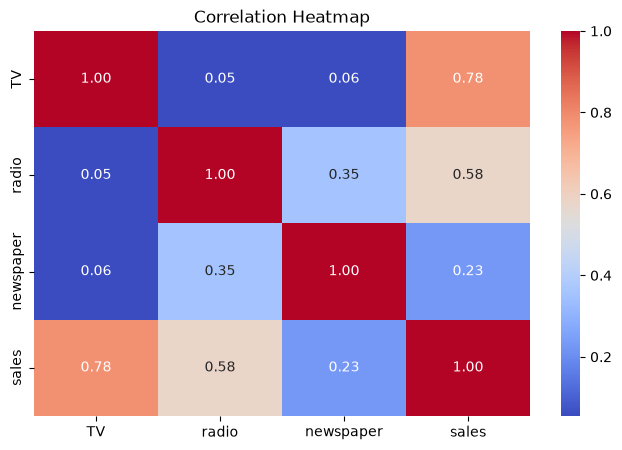

In [12]:

plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


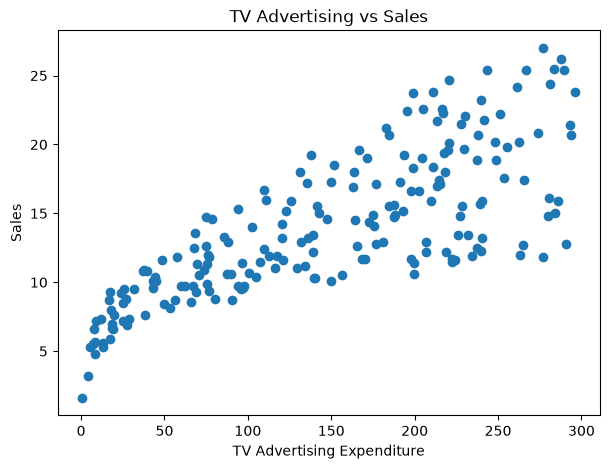

In [13]:

plt.figure(figsize=(7, 5))

plt.scatter(df["TV"], df["sales"])

plt.title("TV Advertising vs Sales")
plt.xlabel("TV Advertising Expenditure")
plt.ylabel("Sales")

plt.show()


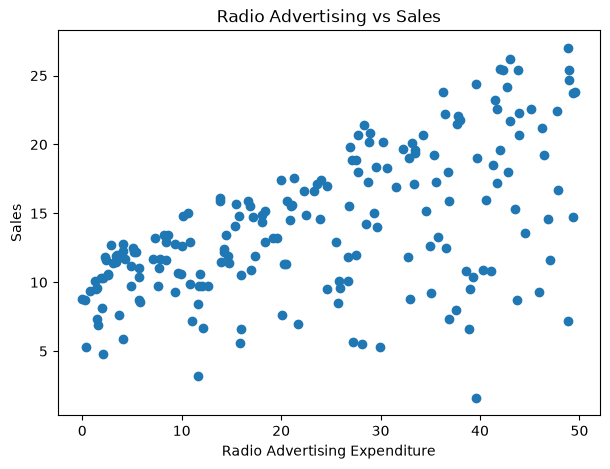

In [14]:

plt.figure(figsize=(7, 5))

plt.scatter(df["radio"], df["sales"])

plt.title("Radio Advertising vs Sales")
plt.xlabel("Radio Advertising Expenditure")
plt.ylabel("Sales")

plt.show()


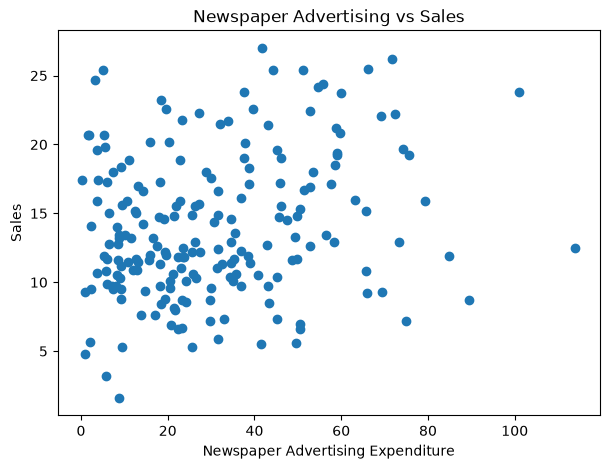

In [15]:

plt.figure(figsize=(7, 5))

plt.scatter(df["newspaper"], df["sales"])

plt.title("Newspaper Advertising vs Sales")
plt.xlabel("Newspaper Advertising Expenditure")
plt.ylabel("Sales")

plt.show()


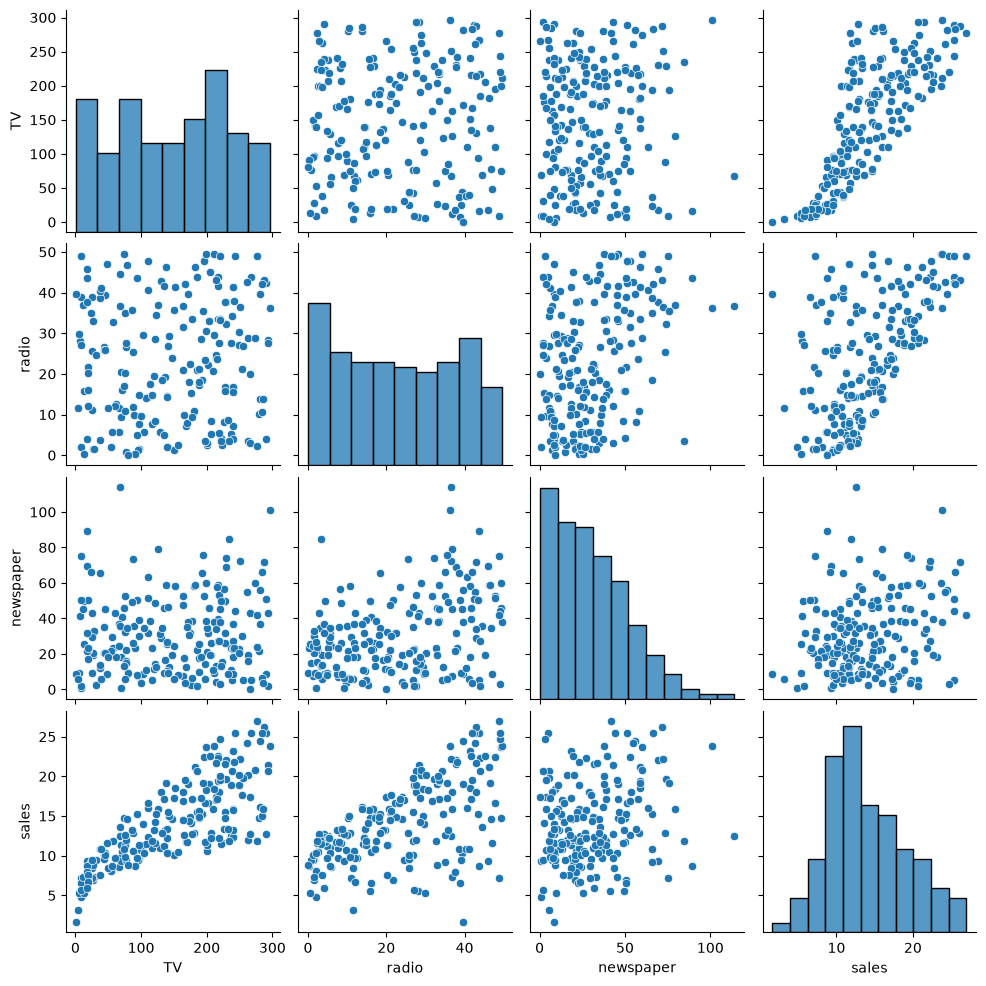

In [16]:
sns.pairplot(df)
plt.show()

In [17]:
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

print("Input features (X):")
display(X.head())

print("Target variable (y):")
display(y.head())

Input features (X):


,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


Target variable (y):


0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: sales, dtype: float64

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (160, 3)
Testing input shape: (40, 3)
Training target shape: (160,)
Testing target shape: (40,)


In [19]:
# Create the Linear Regression model
lr_model = LinearRegression()

# Train the model using training data
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [20]:
# Predict sales using the testing data
y_pred = lr_model.predict(X_test)

print("Actual Sales (first 10 values):")
print(y_test.head(10).values)

print("\nPredicted Sales (first 10 values):")
print(y_pred[:10])

Actual Sales (first 10 values):
[16.9 22.4 21.4  7.3 24.7 12.6 22.3  8.4 11.5 14.9]

Predicted Sales (first 10 values):
[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967]


In [21]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Evaluation")
print("----------------------------------")
print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R-squared Score (R2):", round(r2, 3))

Linear Regression Model Evaluation
----------------------------------
Mean Absolute Error (MAE): 1.461
Root Mean Squared Error (RMSE): 1.782
R-squared Score (R2): 0.899


In [22]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

print("Polynomial Regression tools imported successfully!")

Polynomial Regression tools imported successfully!


In [23]:
# Create and train the Polynomial Regression model
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

print("Polynomial Regression model trained successfully!")

Polynomial Regression model trained successfully!


In [24]:
# Predict sales using the Polynomial Regression model
y_poly_pred = poly_model.predict(X_test)

print("Actual Sales (first 10 values):")
print(y_test.head(10).values)

print("\nPolynomial Regression Predictions (first 10 values):")
print(y_poly_pred[:10])

Actual Sales (first 10 values):
[16.9 22.4 21.4  7.3 24.7 12.6 22.3  8.4 11.5 14.9]

Polynomial Regression Predictions (first 10 values):
[17.25443578 22.7193321  20.42799436  7.542709   24.37103037 12.55927164
 22.80784986  8.34371358 12.0586023  15.69024565]


In [25]:
# Calculate evaluation metrics for Polynomial Regression
poly_mae = mean_absolute_error(y_test, y_poly_pred)
poly_mse = mean_squared_error(y_test, y_poly_pred)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test, y_poly_pred)

print("Polynomial Regression Model Evaluation")
print("--------------------------------------")
print("Mean Absolute Error (MAE):", round(poly_mae, 3))
print("Root Mean Squared Error (RMSE):", round(poly_rmse, 3))
print("R-squared Score (R2):", round(poly_r2, 3))

Polynomial Regression Model Evaluation
--------------------------------------
Mean Absolute Error (MAE): 0.526
Root Mean Squared Error (RMSE): 0.643
R-squared Score (R2): 0.987


In [26]:
# Create a comparison table
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MAE": [mae, poly_mae],
    "RMSE": [rmse, poly_rmse],
    "R2 Score": [r2, poly_r2]
})

display(comparison.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.461,1.782,0.899
1,Polynomial Regression,0.526,0.643,0.987


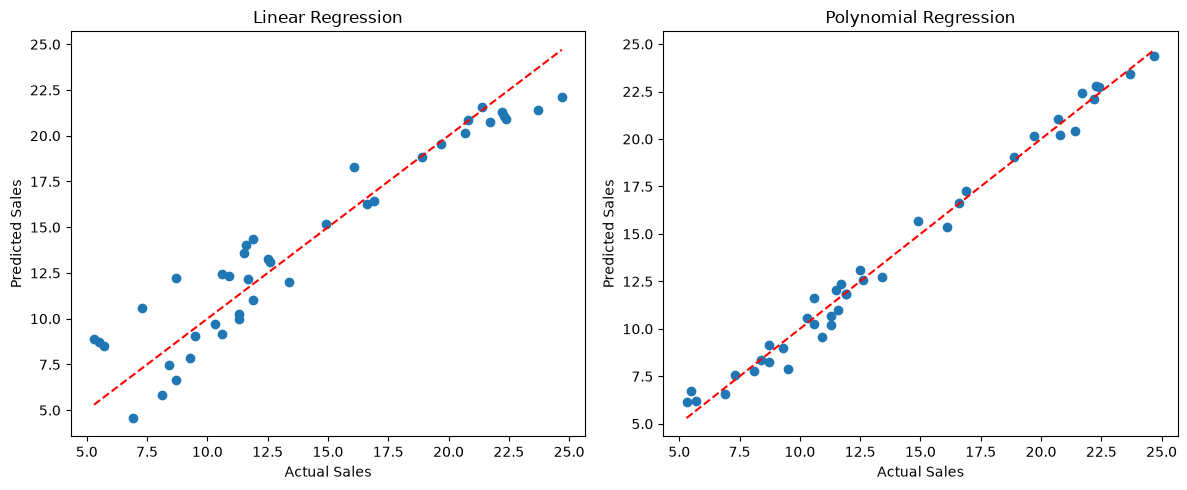

In [27]:
# Compare actual and predicted sales for both models
plt.figure(figsize=(12, 5))

# Linear Regression plot
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.title("Linear Regression")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

# Polynomial Regression plot
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_poly_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.title("Polynomial Regression")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.tight_layout()
plt.show()

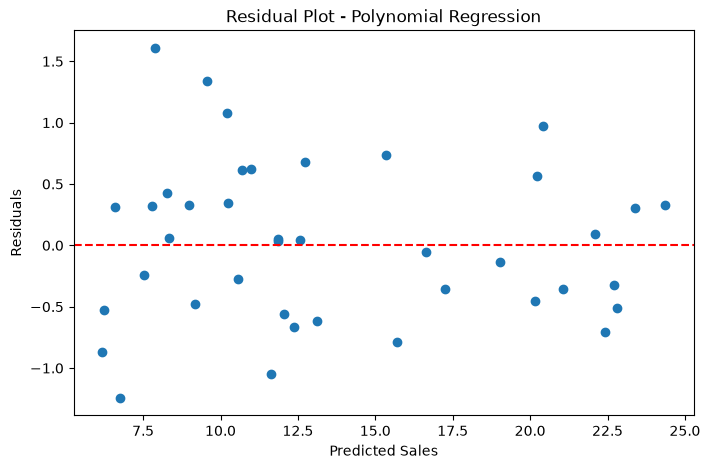

Best model based on RMSE: Polynomial Regression


In [28]:
# Select the model with the lower RMSE
if rmse <= poly_rmse:
    best_model_name = "Linear Regression"
    best_predictions = y_pred
else:
    best_model_name = "Polynomial Regression"
    best_predictions = y_poly_pred

# Calculate residuals
residuals = y_test - best_predictions

# Plot the residuals
plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals)
plt.axhline(y=0, color="red", linestyle="--")

plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.show()

print("Best model based on RMSE:", best_model_name)

,Advertising Channel,Coefficient
1,radio,0.189
0,TV,0.045
2,newspaper,0.003


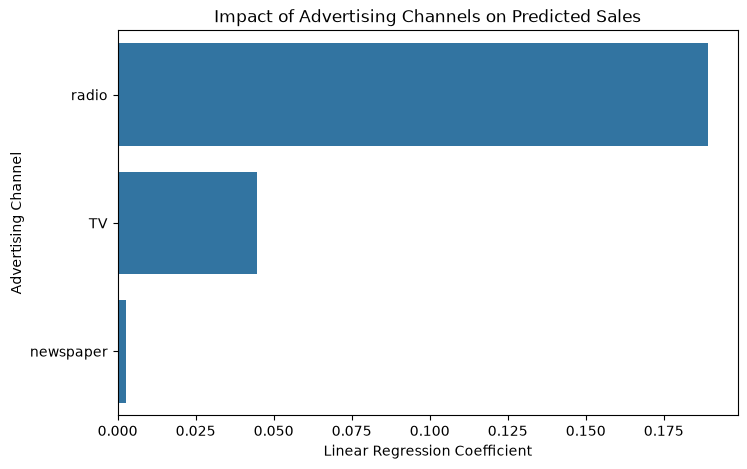

In [29]:
# Get feature names and their Linear Regression coefficients
feature_impact = pd.DataFrame({
    "Advertising Channel": X.columns,
    "Coefficient": lr_model.coef_
})

# Sort channels by coefficient
feature_impact = feature_impact.sort_values(
    by="Coefficient", ascending=False
)

display(feature_impact.round(3))

# Visualize the coefficients
plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_impact,
    x="Coefficient",
    y="Advertising Channel"
)

plt.title("Impact of Advertising Channels on Predicted Sales")
plt.xlabel("Linear Regression Coefficient")
plt.ylabel("Advertising Channel")
plt.show()

# 8. Conclusion

In this project, we developed a machine learning model to predict product sales based on TV, radio, and newspaper advertising expenditure.

## Key Steps Completed

- Loaded and explored the Advertising dataset.
- Checked missing values and descriptive statistics.
- Visualized relationships using scatter plots, a pairplot, and a correlation heatmap.
- Split the dataset into training and testing sets.
- Trained Linear Regression and Polynomial Regression models.
- Evaluated both models using MAE, RMSE, and R² score.
- Compared model performance and plotted prediction errors.
- Analyzed Linear Regression coefficients to understand the estimated impact of advertising channels.

## Final Observation

The model with the lower RMSE performed better on the test dataset according to that metric. The advertising channel coefficients helped us understand how each advertising feature relates to predicted sales while holding the other features constant.

## Learning Outcome

This project provided practical experience in data preprocessing, exploratory data analysis, data visualization, regression modeling, model evaluation, and interpreting machine learning results using Python.
